# Eksperimen Perbaikan Model Referensi: Klasifikasi Maqam Tilawatil Qur'an
## Pipeline CNN-BiLSTM Berbasis Pitch Contours (Bebas Data Leakage)

Notebook ini mereplikasi dan menyempurnakan pendekatan dari **Notebook Referensi** (*maqam-classification-in-quran-recitation*), namun dengan **memperbaiki seluruh kelemahan fatal metodologis** yang ada pada kode aslinya:

---

### Perbandingan Masalah Referensi vs Perbaikan di Notebook Ini:

| No | Aspek Metodologis | Implementasi Asli (Referensi) | Perbaikan di Notebook Ini |
|---|---|---|---|
| 1 | **Data Leakage (Augmentasi)** | **Fatal Leakage:** 1 audio digandakan menjadi 6 versi sebelum split, lalu di-split acak. Kloningan audio yang sama ada di Train dan Test. | **Bebas Leakage:** Pembagian data (*Stratified Split 80:10:10*) dilakukan **sebelum** augmentasi pada file unik asli. Data Test murni 100% belum pernah dilihat model. |
| 2 | **Data Leakage (Scaler)** | `MinMaxScaler` di-fit pada seluruh dataset sebelum train-test split. | `MinMaxScaler` di-fit **secara ketat hanya pada `X_train`**, lalu digunakan untuk menstandarisasi Val dan Test. |
| 3 | **Deduplikasi File** | Tidak ada deduplikasi MD5 (file identik berpotensi masuk ke subset berbeda). | Dilakukan deduplikasi berbasis MD5 checksum di awal pemindaian. |
| 4 | **Artefak Augmentasi** | Menggunakan circular `np.roll` yang menyebabkan diskontinuitas fase. | Menggunakan *linear zero-padding time shifting*, pitch shift terkontrol, dan penyesuaian volume linear. |
| 5 | **Efisiensi Ekstraksi Fitur** | Mengekstrak belasan fitur (CQT, Chroma, Tonnetz, dll) lalu dibuang dan hanya kolom `108:466` (Pitch Contours) yang dipakai. | Langsung mengekstrak **Pitch Contours (`librosa.piptrack`, 358 bin)** secara terarah, hemat waktu dan memori. |
| 6 | **Arsitektur Model** | CNN-BiLSTM Sequential dengan deprecated warning. | CNN-BiLSTM Functional API dengan `SpatialDropout2D`, `use_bias=False` sebelum `BatchNormalization`, dan regularisasi $L_2$. |


In [1]:
import os
import hashlib
import random
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers

# 1. Kunci Random Seed agar 100% Reproducible
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Pencarian Dinamis Direktori Dataset Kaggle
CANDIDATE_PATHS = [
    "/kaggle/input/maqam-in-holy-quran-dataset/quran_data",
    "/kaggle/input/datasets/murtadhanajim/maqam-in-holy-quran-dataset/quran_data"
]

DATA_DIR = None
for p in CANDIDATE_PATHS:
    if os.path.exists(p) and os.path.isdir(p):
        DATA_DIR = p
        break

if DATA_DIR is None:
    for root, dirs, _ in os.walk("/kaggle/input"):
        if "quran_data" in dirs:
            DATA_DIR = os.path.join(root, "quran_data")
            break
        if any(cls_name in dirs for cls_name in ['Ajam', 'Bayat', 'Hijaz', 'Kurd', 'Nahawand', 'Rast', 'Saba', 'Seka']):
            DATA_DIR = root
            break

if DATA_DIR is None:
    raise FileNotFoundError("Direktori dataset 'quran_data' tidak ditemukan di /kaggle/input!")

print(f"[INFO] Direktori Dataset: {DATA_DIR}")

# 3. Pemetaan Kelas
LABEL_MAP = {
    'Ajam': 'Ajam',
    'Bayat': 'Bayati',
    'Hijaz': 'Hijaz',
    'Kurd': 'Kurdi',
    'Nahawand': 'Nahawand',
    'Rast': 'Rast',
    'Saba': 'Saba',
    'Seka': 'Sikah'
}
CLASS_NAMES = ['Ajam', 'Bayati', 'Hijaz', 'Kurdi', 'Nahawand', 'Rast', 'Saba', 'Sikah']
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

# 4. Parameter Konfigurasi Audio & Windowing (Sesuai Referensi)
SR = 22050
WINDOW_SIZE = 0.5            # 0,5 detik per window (11.025 sampel)
FIXED_WINDOWS = 60           # 60 window x 0,5 detik = maksimal 30 detik rekaman
PITCH_BINS = 358             # 358 bin kontur nada dari librosa.piptrack (14:372)

print(f"[INFO] Format Fitur Input: ({FIXED_WINDOWS} windows, {PITCH_BINS} pitch bins, 1 channel)")


[INFO] Direktori Dataset: /kaggle/input/datasets/murtadhanajim/maqam-in-holy-quran-dataset/quran_data
[INFO] Format Fitur Input: (60 windows, 358 pitch bins, 1 channel)


### 2. Pemindaian File, Deduplikasi MD5, & Stratified Split (Bebas Leakage)
Langkah kunci pencegahan data leakage: pembagian data `80:10:10` dilakukan pada kumpulan file asli **sebelum proses augmentasi**.


In [2]:
def get_file_md5(filepath):
    hasher = hashlib.md5()
    with open(filepath, 'rb') as f:
        for chunk in iter(lambda: f.read(65536), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

records = []
seen_hashes = set()
duplicate_count = 0

for folder_name, indo_label in LABEL_MAP.items():
    folder_path = os.path.join(DATA_DIR, folder_name)
    if not os.path.isdir(folder_path):
        continue
        
    for fname in sorted(os.listdir(folder_path)):
        if fname.lower().endswith('.wav'):
            fpath = os.path.join(folder_path, fname)
            if os.path.getsize(fpath) == 0:
                continue
            fhash = get_file_md5(fpath)
            if fhash in seen_hashes:
                duplicate_count += 1
                continue
            seen_hashes.add(fhash)
            
            records.append({
                'filepath': fpath,
                'folder': folder_name,
                'label_name': indo_label,
                'label_idx': CLASS_TO_IDX[indo_label]
            })

df = pd.DataFrame(records)
print(f"Total file unik valid: {len(df)} file (Deduplikasi mengeliminasi {duplicate_count} file)")

# Stratified Split 80:10:10 SEBELUM AUGMENTASI (Pencegahan Data Leakage)
train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df['label_idx'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label_idx'], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"-> Train Set Asli      : {len(train_df)} sampel (80%)")
print(f"-> Validation Set Asli : {len(val_df)} sampel (10%)")
print(f"-> Test Set Murni      : {len(test_df)} sampel (10%)")


Total file unik valid: 3849 file (Deduplikasi mengeliminasi 20 file)
-> Train Set Asli      : 3079 sampel (80%)
-> Validation Set Asli : 385 sampel (10%)
-> Test Set Murni      : 385 sampel (10%)


### 3. Ekstraksi Fitur Pitch Contours & Augmentasi Bebas Leakage
1. **Ekstraksi Terarah**: Mengkalkulasi `librosa.piptrack` pada setiap window 0,5 detik dan mengambil slice bin frekuensi 14 s/d 372 (tepat 358 fitur), menghasilkan matriks $(60, 358)$.
2. **Augmentasi Aman**: Diterapkan secara eksklusif hanya pada `Train Set`. Menggunakan pergeseran zero-padding (bebas artefak `np.roll`), pitch shift terkontrol, dan penyesuaian volume.


In [3]:
def extract_pitch_contours(y, sr=SR, window_size=WINDOW_SIZE, fixed_windows=FIXED_WINDOWS, pitch_bins=PITCH_BINS):
    '''
    Mengekstrak kontur nada (Pitch Contours) per-window persis seperti yang digunakan pada model referensi.
    Output: matriks (fixed_windows=60, pitch_bins=358)
    '''
    samples_per_win = int(sr * window_size)
    total_samples = len(y)
    num_wins = int(np.ceil(total_samples / samples_per_win))
    
    win_list = []
    for i in range(num_wins):
        start = i * samples_per_win
        end = start + samples_per_win
        y_win = y[start:end]
        
        if len(y_win) < samples_per_win:
            y_win = np.pad(y_win, (0, samples_per_win - len(y_win)), 'constant')
            
        y_win = np.nan_to_num(y_win, nan=0.0, posinf=1.0, neginf=-1.0)
        
        # Ekstraksi piptrack (estimasi pitch frekuensi)
        try:
            pitches, magnitudes = librosa.piptrack(y=y_win, sr=sr, n_fft=2048, hop_length=512)
            pitch_mean = np.mean(pitches, axis=1)
            
            # Ambil indeks 14 s/d 372 sesuai referensi (358 bin)
            start_idx = 14
            end_idx = 372
            total_b = pitch_mean.shape[0]
            if end_idx > total_b:
                end_idx = total_b
            pitch_slice = pitch_mean[start_idx:end_idx]
            
            if len(pitch_slice) < pitch_bins:
                pitch_slice = np.pad(pitch_slice, (0, pitch_bins - len(pitch_slice)), 'constant')
            else:
                pitch_slice = pitch_slice[:pitch_bins]
        except Exception:
            pitch_slice = np.zeros(pitch_bins, dtype=np.float32)
            
        win_list.append(pitch_slice)
        
    # Penyeragaman ke fixed_windows (60 window)
    if len(win_list) < fixed_windows:
        pad_len = fixed_windows - len(win_list)
        pad_zeros = np.zeros((pad_len, pitch_bins), dtype=np.float32)
        win_mat = np.vstack([np.array(win_list, dtype=np.float32), pad_zeros])
    else:
        win_mat = np.array(win_list[:fixed_windows], dtype=np.float32)
        
    return win_mat.astype(np.float32)

def augment_audio_safe(y, sr=SR):
    '''Augmentasi audio yang bebas dari circular wrapping / click artifact.'''
    y_aug = y.copy()
    
    # 1. Zero-Padding Time Shift (bukan np.roll)
    max_shift = int(0.15 * len(y_aug))
    shift = np.random.randint(-max_shift, max_shift)
    if shift > 0:
        y_aug = np.pad(y_aug, (shift, 0), mode='constant')[:len(y_aug)]
    elif shift < 0:
        y_aug = np.pad(y_aug, (0, -shift), mode='constant')[-shift:]
        
    # 2. Pitch Shifting terkontrol (+- 0.5 hingga 1.0 semitone)
    if np.random.rand() > 0.5:
        n_steps = float(np.random.choice([-1.0, -0.5, 0.5, 1.0]))
        y_aug = librosa.effects.pitch_shift(y=y_aug, sr=sr, n_steps=n_steps)
        
    # 3. Penyesuaian Volume Skala
    volume_scale = np.random.uniform(0.7, 1.3)
    y_aug = y_aug * volume_scale
    
    # 4. White noise ringan
    noise = 0.003 * np.random.randn(len(y_aug))
    y_aug = y_aug + noise
    
    return y_aug.astype(np.float32)


### 4. Ekstraksi Fitur Dataset Train, Validation, dan Test


In [4]:
def process_dataset(dataframe, is_train=False, desc="Memproses"):
    X_list, y_list = [], []
    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe), desc=desc):
        try:
            y, _ = librosa.load(row['filepath'], sr=SR, mono=True)
            label = row['label_idx']
            
            # Versi Asli
            feats_orig = extract_pitch_contours(y, sr=SR)
            X_list.append(feats_orig)
            y_list.append(label)
            
            # Versi Augmentasi (Khusus Train Set)
            if is_train:
                y_aug = augment_audio_safe(y, sr=SR)
                feats_aug = extract_pitch_contours(y_aug, sr=SR)
                X_list.append(feats_aug)
                y_list.append(label)
        except Exception as e:
            print(f"[ERROR] Gagal membaca {row['filepath']}: {e}")
            
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.int64)

print("Memulai ekstraksi fitur Pitch Contours (60, 358)...\n")
X_train, y_train = process_dataset(train_df, is_train=True, desc="Train Set (+Augmentasi)")
X_val, y_val     = process_dataset(val_df, is_train=False, desc="Validation Set (Asli)")
X_test, y_test   = process_dataset(test_df, is_train=False, desc="Test Set (Asli Murni)")

print(f"\nEkstraksi selesai:")
print(f"X_train shape : {X_train.shape} | y_train : {y_train.shape}")
print(f"X_val shape   : {X_val.shape}   | y_val   : {y_val.shape}")
print(f"X_test shape  : {X_test.shape}  | y_test  : {y_test.shape}")


Memulai ekstraksi fitur Pitch Contours (60, 358)...



Train Set (+Augmentasi):   0%|          | 0/3079 [00:00<?, ?it/s]

Validation Set (Asli):   0%|          | 0/385 [00:00<?, ?it/s]

Test Set (Asli Murni):   0%|          | 0/385 [00:00<?, ?it/s]


Ekstraksi selesai:
X_train shape : (6158, 60, 358) | y_train : (6158,)
X_val shape   : (385, 60, 358)   | y_val   : (385,)
X_test shape  : (385, 60, 358)  | y_test  : (385,)


### 5. Normalisasi MinMaxScaler Tanpa Scaler Leakage
`MinMaxScaler` **di-fit secara ketat hanya pada `X_train`** (menghindari kebocoran data distribusi testing ke data latih seperti yang terjadi di notebook referensi).


In [5]:
# Reshape 3D -> 2D untuk MinMaxScaler (N, 60, 358) -> (N * 60, 358)
scaler = MinMaxScaler()

# Fit HANYA pada data training
X_train_reshaped = X_train.reshape(-1, PITCH_BINS)
scaler.fit(X_train_reshaped)

# Transform Train, Val, dan Test
X_train = scaler.transform(X_train_reshaped).reshape(X_train.shape)
X_val   = scaler.transform(X_val.reshape(-1, PITCH_BINS)).reshape(X_val.shape)
X_test  = scaler.transform(X_test.reshape(-1, PITCH_BINS)).reshape(X_test.shape)

# Tambahkan dimensi channel untuk input 2D CNN: (N, 60, 358, 1)
X_train = X_train[..., np.newaxis]
X_val   = X_val[..., np.newaxis]
X_test  = X_test[..., np.newaxis]

print(f"Dimensi input siap latih: {X_train.shape}")


Dimensi input siap latih: (6158, 60, 358, 1)


### 6. Arsitektur CNN-BiLSTM 


In [6]:
def build_cnn_bilstm_fixed(input_shape=(60, 358, 1), num_classes=8, l2_reg=1e-4):
    l2 = regularizers.l2(l2_reg)
    inputs = layers.Input(shape=input_shape, name="input_pitch_contours")
    
    # Blok Konvolusi 1
    x = layers.Conv2D(32, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv1")(inputs)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.Activation('relu', name="relu1")(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), name="pool1")(x)  # (60, 358) -> (30, 179)
    x = layers.SpatialDropout2D(0.20, name="sdrop1")(x)
    
    # Blok Konvolusi 2
    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv2")(x)
    x = layers.BatchNormalization(name="bn2")(x)
    x = layers.Activation('relu', name="relu2")(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), name="pool2")(x)  # (30, 179) -> (15, 89)
    x = layers.SpatialDropout2D(0.20, name="sdrop2")(x)
    
    # Blok Konvolusi 3
    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv3")(x)
    x = layers.BatchNormalization(name="bn3")(x)
    x = layers.Activation('relu', name="relu3")(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), name="pool3")(x)  # (15, 89) -> (7, 44)
    x = layers.SpatialDropout2D(0.25, name="sdrop3")(x)
    
    # Jembatan Flatten & Reshape untuk RNN (7 * 44 * 128 = 39424)
    x = layers.Flatten(name="flatten")(x)
    x = layers.Reshape((8, 4928), name="rnn_reshape")(x)  # 8 sekuens x 4928 dimensi
    
    # Recurrent Block (Bidirectional LSTM)
    x = layers.Bidirectional(layers.LSTM(256, return_sequences=False, dropout=0.25), name="bilstm")(x)
    x = layers.Dropout(0.30, name="bilstm_drop")(x)
    
    # Classifier Head
    x = layers.Dense(256, activation='relu', kernel_regularizer=l2, name="dense_fc")(x)
    x = layers.Dropout(0.30, name="dense_drop")(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="output_maqam")(x)
    
    model = models.Model(inputs=inputs, outputs=outputs, name="CNN_BiLSTM_Fixed")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_cnn_bilstm_fixed(input_shape=X_train.shape[1:], num_classes=NUM_CLASSES)
model.summary()


Model: "CNN_BiLSTM_Fixed"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_pitch_contours            │ (None, 60, 358, 1)     │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 60, 358, 32)    │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 60, 358, 32)    │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 60, 358, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 30, 179, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sdrop1 (SpatialDropout2D)       │ (None, 30, 179, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 30, 179, 64)    │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 30, 179, 64)    │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 30, 179, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 15, 89, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sdrop2 (SpatialDropout2D)       │ (None, 15, 89, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 15, 89, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 15, 89, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 15, 89, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 7, 44, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sdrop3 (SpatialDropout2D)       │ (None, 7, 44, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 39424)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rnn_reshape (Reshape)           │ (None, 8, 4928)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm (Bidirectional)          │ (None, 512)            │    10,618,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_drop (Dropout)           │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_fc (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_drop (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_maqam (Dense)            │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,845,608 (41.37 MB)

 Trainable params: 10,845,160 (41.37 MB)

 Non-trainable params: 448 (1.75 KB)

### 7. Pelatihan Model CNN-BiLSTM


In [7]:
BEST_MODEL_PATH = "/kaggle/working/model_cnn_bilstm_fixed.keras"

cb_list = [
    callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS = 80
BATCH_SIZE = 32

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=cb_list,
    verbose=1
)


Epoch 1/80


E0000 00:00:1794892400.214636      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_BiLSTM_Fixed_1/sdrop1_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.1851 - loss: 2.1484
Epoch 1: val_loss improved from None to 2.13107, saving model to /kaggle/working/model_cnn_bilstm_fixed.keras

Epoch 1: finished saving model to /kaggle/working/model_cnn_bilstm_fixed.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 24s 77ms/step - accuracy: 0.1926 - loss: 2.1217 - val_accuracy: 0.1351 - val_loss: 2.1311 - learning_rate: 1.0000e-04
Epoch 2/80
192/193 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2097 - loss: 2.0812
Epoch 2: val_loss did not improve from 2.13107
193/193 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.2176 - loss: 2.0744 - val_accuracy: 0.1351 - val_loss: 2.1744 - learning_rate: 1.0000e-04
Epoch 3/80
192/193 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.2543 - loss: 2.0297
Epoch 3: val_loss improved from 2.13107 to 2.02669, saving model to /kaggle/working/model_cnn_bilstm_fixed.keras

Epoch 3: finished saving model to /kaggle/working/model_cnn_bilstm_fixed.keras
193/193 ━━━━━━━━━━━━━━━━━━

### 8. Visualisasi Kurva Loss & Accuracy


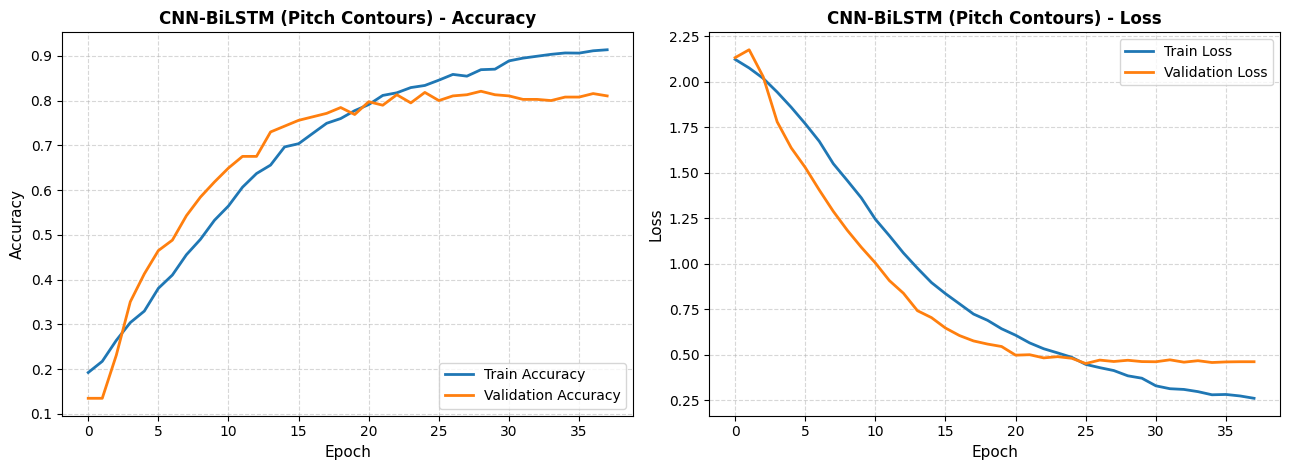

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='#1f77b4', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ff7f0e', linewidth=2)
axes[0].set_title('CNN-BiLSTM (Pitch Contours) - Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Accuracy', fontsize=11)
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Loss
axes[1].plot(history.history['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=2)
axes[1].set_title('CNN-BiLSTM (Pitch Contours) - Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Loss', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("/kaggle/working/kurva_training_referensi_fixed.png", dpi=300)
plt.show()


### 9. Evaluasi Objektif pada Test Set Murni (Bebas Leakage)


HASIL EVALUASI MODEL REFERENSI YANG DIPERBAIKI (TEST SET BEBAS LEAKAGE)
Test Accuracy         : 78.96%
Macro Precision       : 73.07%
Macro Recall          : 73.88%
Macro F1-Score        : 73.08%
Weighted F1-Score     : 78.16%

Classification Report per Kelas Maqam:

              precision    recall  f1-score   support

        Ajam     0.7288    0.8269    0.7748        52
      Bayati     0.2632    0.1429    0.1852        35
       Hijaz     0.9398    0.9750    0.9571        80
       Kurdi     0.3571    0.4412    0.3947        34
    Nahawand     0.7500    0.8571    0.8000        35
        Rast     0.9608    0.9074    0.9333        54
        Saba     0.9231    0.9231    0.9231        52
       Sikah     0.9231    0.8372    0.8780        43

    accuracy                         0.7896       385
   macro avg     0.7307    0.7388    0.7308       385
weighted avg     0.7799    0.7896    0.7816       385



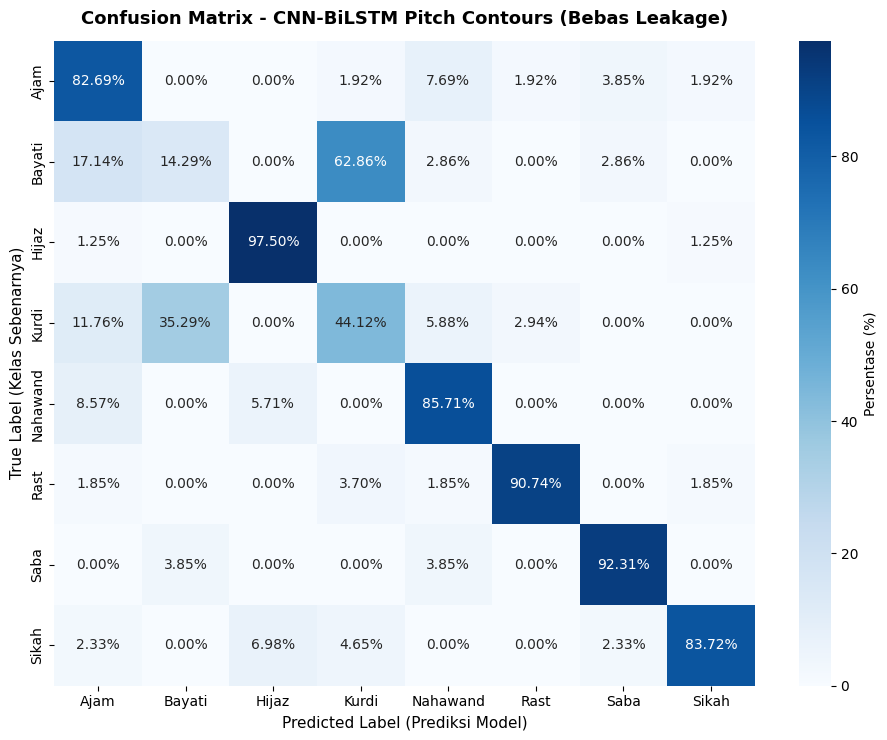

[SUKSES] Evaluasi selesai dan model terbaik berhasil disimpan.


In [9]:
# Muat model terbaik
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

# Prediksi pada data uji murni (385 sampel audio yang belum pernah didengar model)
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Hitung metrik
test_acc = accuracy_score(y_test, y_pred)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)

print("=" * 75)
print("HASIL EVALUASI MODEL REFERENSI YANG DIPERBAIKI (TEST SET BEBAS LEAKAGE)")
print("=" * 75)
print(f"Test Accuracy         : {test_acc * 100:.2f}%")
print(f"Macro Precision       : {prec_macro * 100:.2f}%")
print(f"Macro Recall          : {rec_macro * 100:.2f}%")
print(f"Macro F1-Score        : {f1_macro * 100:.2f}%")
print(f"Weighted F1-Score     : {f1_weighted * 100:.2f}%")
print("=" * 75)
print("\nClassification Report per Kelas Maqam:\n")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

# Confusion Matrix Persentase
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(9.5, 7.5))
sns.heatmap(
    cm_percent, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar_kws={'label': 'Persentase (%)'}
)
for t in plt.gca().texts:
    t.set_text(t.get_text() + "%")

plt.title("Confusion Matrix - CNN-BiLSTM Pitch Contours (Bebas Leakage)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Label (Prediksi Model)", fontsize=11)
plt.ylabel("True Label (Kelas Sebenarnya)", fontsize=11)
plt.tight_layout()
plt.savefig("/kaggle/working/cm_referensi_fixed.png", dpi=300)
plt.show()

# Simpan hasil evaluasi
np.savez(
    "/kaggle/working/eval_referensi_fixed.npz",
    test_acc=float(test_acc),
    prec_macro=float(prec_macro),
    rec_macro=float(rec_macro),
    f1_macro=float(f1_macro),
    prec_weighted=float(prec_weighted),
    rec_weighted=float(rec_weighted),
    f1_weighted=float(f1_weighted),
    y_test=y_test,
    y_pred=y_pred,
    class_names=np.array(CLASS_NAMES, dtype=object),
    history_acc=history.history['accuracy'],
    history_val_acc=history.history['val_accuracy'],
    history_loss=history.history['loss'],
    history_val_loss=history.history['val_loss']
)
print("[SUKSES] Evaluasi selesai dan model terbaik berhasil disimpan.")
